
# Industrial Defect Detection using Vision Transformers

**MAAI901 – Deep Learning for Visual Data**

This notebook investigates whether Vision Transformers can identify rare industrial surface defects in the KolektorSDD2 dataset.

The experiments compare ResNet-50 with three Vision Transformer configurations: a frozen ViT, a fine-tuned ViT, and a fine-tuned ViT with class-weighted loss.

The models are evaluated using accuracy, precision, recall, F1-score and average precision. The study also examines training variability, input resolution and decision thresholds.


In [1]:
# Connecting Google Drive to save the experiment results
from google.colab import drive
drive.mount("/content/drive")

# Folder for the final results
RESULTS_DIR = "/content/drive/MyDrive/ksdd2_final_results"

from pathlib import Path

Path(RESULTS_DIR).mkdir(parents=True, exist_ok=True)

print("Results will be saved to:", RESULTS_DIR)


Mounted at /content/drive
Results will be saved to: /content/drive/MyDrive/ksdd2_final_results


In [2]:
# Installing the library used for pretrained image models
!pip -q install timm

# Importing Libraries for working with data
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Libraries for images
from PIL import Image
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader

# Libraries for deep learning
import torch
import torch.nn as nn
import torch.optim as optim
import timm

# Libraries for model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve
)

# Checking whether Colab has a GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Using device: cuda
GPU: Tesla T4


In [3]:
import zipfile
from pathlib import Path

# Location of the dataset ZIP in Google Drive
zip_path = "/content/drive/MyDrive/ksdd2/archive.zip"

# Extract the dataset into Colab for faster access
DATA_DIR = "/content/ksdd2_data"

Path(DATA_DIR).mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_file:
    zip_file.extractall(DATA_DIR)

print("Dataset extracted successfully!")

# Check the folders inside the extracted dataset
print("Contents:", [p.name for p in Path(DATA_DIR).iterdir()])


Dataset extracted successfully!
Contents: ['__MACOSX', 'archive']


In [4]:
from pathlib import Path

# Check what is inside the archive folder
dataset_folder = Path(DATA_DIR) / "archive"

print("Folders and files inside archive:")

for item in sorted(dataset_folder.iterdir()):
    print(item.name, "- Folder" if item.is_dir() else "- File")


Folders and files inside archive:
split_weakly_0.pyb - File
split_weakly_126.pyb - File
split_weakly_16.pyb - File
split_weakly_246.pyb - File
split_weakly_53.pyb - File
test - Folder
train - Folder


In [5]:
from pathlib import Path

# Main dataset folder
DATASET_PATH = Path(DATA_DIR) / "archive"

train_folder = DATASET_PATH / "train"
test_folder = DATASET_PATH / "test"

# Count PNG images in each folder
train_files = list(train_folder.rglob("*.png"))
test_files = list(test_folder.rglob("*.png"))

print("Training PNG files:", len(train_files))
print("Testing PNG files:", len(test_files))

# Show a few filenames to understand the naming pattern
print("\nExample training files:")
for file in train_files[:8]:
    print(file.name)


Training PNG files: 4664
Testing PNG files: 2008

Example training files:
11700.png
10608_GT.png
11921_GT.png
12285_GT.png
11514_GT.png
10022.png
12277_GT.png
10887_GT.png


In [6]:
# Checking for the duplicate files found in the earlier experiment

duplicate_names = [
    "10301 (copy).png",
    "10301_GT (copy).png"
]

for name in duplicate_names:
    file_path = train_folder / name

    if file_path.exists():
        print("Found duplicate:", name)
    else:
        print("Not found:", name)

# Counting the actual images, excluding masks and duplicate copies
train_images = sorted([
    f for f in train_folder.glob("*.png")
    if not f.stem.endswith("_GT") and "(copy)" not in f.name
])

test_images = sorted([
    f for f in test_folder.glob("*.png")
    if not f.stem.endswith("_GT") and "(copy)" not in f.name
])

print("\nTraining images:", len(train_images))
print("Testing images:", len(test_images))
print("Total images:", len(train_images) + len(test_images))


Found duplicate: 10301 (copy).png
Found duplicate: 10301_GT (copy).png

Training images: 2331
Testing images: 1004
Total images: 3335


In [7]:
# Creating labels using the defect masks
def create_labels(image_files):
    data = []

    for image_path in image_files:
        mask_path = image_path.with_name(image_path.stem + "_GT.png")

        if not mask_path.exists():
            raise FileNotFoundError(f"Mask missing: {mask_path}")

        # A non-black pixel means the image contains a defect
        mask = np.array(Image.open(mask_path).convert("L"))
        label = 1 if np.any(mask > 0) else 0

        data.append({
            "image_path": str(image_path),
            "label": label
        })

    return pd.DataFrame(data)


train_df = create_labels(train_images)
test_df = create_labels(test_images)

print("Original training data:")
print(train_df["label"].value_counts().sort_index())

print("\nTest data:")
print(test_df["label"].value_counts().sort_index())


Original training data:
label
0    2085
1     246
Name: count, dtype: int64

Test data:
label
0    894
1    110
Name: count, dtype: int64


In [8]:
from sklearn.model_selection import train_test_split

# Spliting the original training data into training and validation sets
train_data, val_data = train_test_split(
    train_df,
    test_size=0.20,
    stratify=train_df["label"],
    random_state=42
)

# Reseting the row numbers
train_data = train_data.reset_index(drop=True)
val_data = val_data.reset_index(drop=True)

# Keeping the official test set unchanged
test_data = test_df.reset_index(drop=True)

# Checking the number of normal and defective images
for name, data in [
    ("Training", train_data),
    ("Validation", val_data),
    ("Testing", test_data)
]:
    normal = (data["label"] == 0).sum()
    defective = (data["label"] == 1).sum()

    print(f"{name}: {len(data)} images")
    print(f"  Normal: {normal}")
    print(f"  Defective: {defective}")
    print()


Training: 1864 images
  Normal: 1667
  Defective: 197

Validation: 467 images
  Normal: 418
  Defective: 49

Testing: 1004 images
  Normal: 894
  Defective: 110




## Dataset Exploration

Before training the models, a few images are displayed to examine the differences between normal and defective surfaces.

The defect masks show where imperfections are located. Some defects are very small, which may make classification more difficult when images are resized.


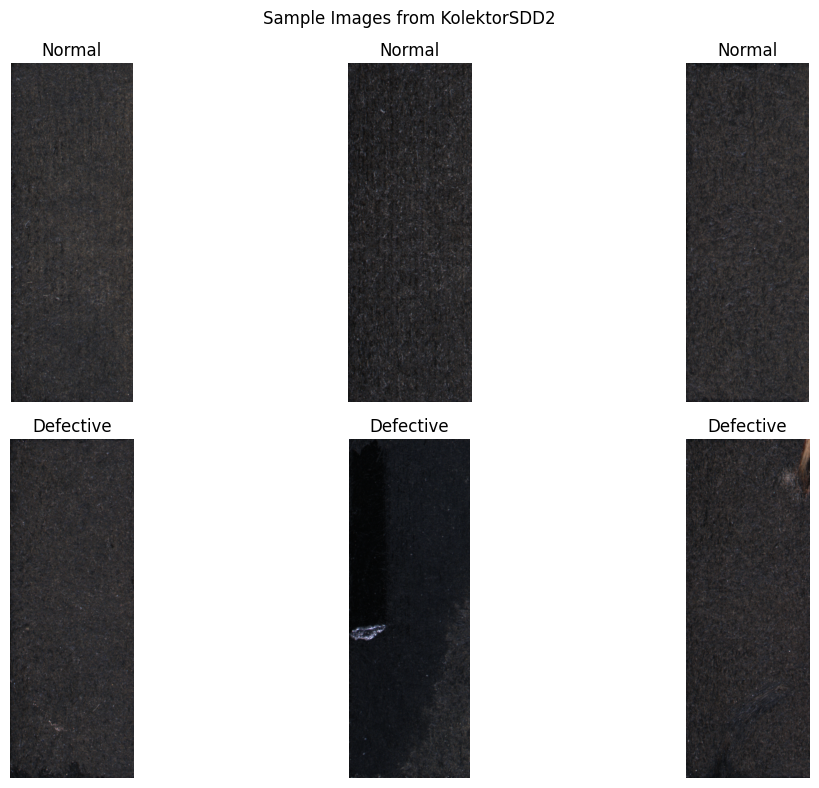

In [9]:
# Displaying three normal images and three defective images
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for row, label in enumerate([0, 1]):
    samples = train_data[train_data["label"] == label].sample(
        n=3, random_state=42
    )

    for col, (_, sample) in enumerate(samples.iterrows()):
        image = Image.open(sample["image_path"]).convert("RGB")

        axes[row, col].imshow(image)
        axes[row, col].set_title(
            "Normal" if label == 0 else "Defective"
        )
        axes[row, col].axis("off")

plt.suptitle("Sample Images from KolektorSDD2")
plt.tight_layout()
plt.show()



### Class Distribution

The dataset contains considerably more normal images than defective images. This imbalance is important because a model could achieve high accuracy by predicting most images as normal.

The chart below shows the number of images in each class across the training, validation and test sets.


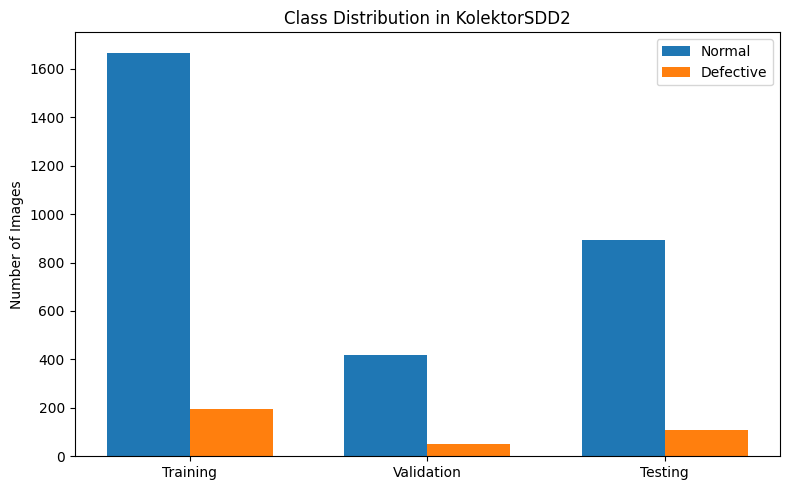


Chart saved successfully!


In [11]:
# Counting the normal and defective images in each split
split_names = ["Training", "Validation", "Testing"]

normal_counts = [
    (train_data["label"] == 0).sum(),
    (val_data["label"] == 0).sum(),
    (test_data["label"] == 0).sum()
]

defect_counts = [
    (train_data["label"] == 1).sum(),
    (val_data["label"] == 1).sum(),
    (test_data["label"] == 1).sum()
]

# Creating a bar chart
x = np.arange(len(split_names))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(x - width / 2, normal_counts, width, label="Normal")
plt.bar(x + width / 2, defect_counts, width, label="Defective")

plt.xticks(x, split_names)
plt.ylabel("Number of Images")
plt.title("Class Distribution in KolektorSDD2")
plt.legend()
plt.tight_layout()

# Saving the chart to the final results folder
plt.savefig(f"{RESULTS_DIR}/class_distribution.png", dpi=300)
plt.show()

print()
print("Chart saved successfully!")



## Image Preprocessing and Augmentation

The images are resized to 384 × 128 pixels to keep their original narrow shape as much as possible.

ImageNet normalisation is used because the models are pretrained on ImageNet.

For training, random flips and small brightness and contrast changes are applied to introduce some variation. Random cropping is avoided because it could remove a small defect while keeping the image labelled as defective.

Validation and test images are only resized and normalised.


In [12]:
#Image size (height, width)
IMAGE_SIZE = (384, 128)

#ImageNet normalisation values
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

#Transformations used for training images
train_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

#Validation and test images do not need random augmentation
eval_transform = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

print("Training and evaluation transforms are ready.")


Training and evaluation transforms are ready.



## Preparing the Data for Training

A custom PyTorch Dataset is used to load each image and its label.

DataLoaders divide the images into smaller batches so they can be passed to the models during training and evaluation.

Training images are shuffled, while validation and test images are kept in a fixed order.


In [13]:
# Dataset class for loading images and labels
class DefectDataset(Dataset):
    def __init__(self, data, transform):
        self.data = data.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row = self.data.iloc[index]

        image = Image.open(row["image_path"]).convert("RGB")
        image = self.transform(image)

        label = int(row["label"])

        return image, label


# Create the datasets
train_dataset = DefectDataset(train_data, train_transform)
val_dataset = DefectDataset(val_data, eval_transform)
test_dataset = DefectDataset(test_data, eval_transform)

# Create DataLoaders
BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

# Check one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))
print("Number of testing batches:", len(test_loader))


Image batch shape: torch.Size([32, 3, 384, 128])
Label batch shape: torch.Size([32])
Number of training batches: 59
Number of validation batches: 15
Number of testing batches: 32



## Model Training and Evaluation

Four model configurations will be compared:

1. ResNet-50 with weighted loss
2. Frozen ViT with standard loss
3. Fine-tuned ViT with standard loss
4. Fine-tuned ViT with weighted loss

Each model will be trained using three random seeds to check how much performance changes between runs.

The best model checkpoint from each run will be selected using validation F1-score for the defective class.


In [14]:
# Set random seeds to make the experiments more reproducible
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# Check the random seed function
set_seed(1)

print("Random seed set to 1.")
print("Device:", device)


Random seed set to 1.
Device: cuda



### Model Selection

ResNet-50 is used as the CNN baseline to compare against the Vision Transformer.

ViT-B/16 is the main model used in this study. It divides images into 16 × 16 patches and uses self-attention to learn relationships between different image regions.

For the ViT experiments, two training approaches are used:
- Frozen backbone: only the classification head is trained.
- Full fine-tuning: all model parameters are updated.

Both models use pretrained ImageNet weights and are adapted to classify images as normal or defective.


In [15]:
# Creating a model for binary defect classification
def create_model(model_type, frozen=False):

    if model_type == "resnet":
        model = timm.create_model(
            "resnet50",
            pretrained=True,
            num_classes=2
        )

    elif model_type == "vit":
        model = timm.create_model(
            "vit_base_patch16_224",
            pretrained=True,
            num_classes=2,
            img_size=IMAGE_SIZE
        )

        # For the frozen ViT, training only the classification head
        if frozen:
            for parameter in model.parameters():
                parameter.requires_grad = False

            for parameter in model.head.parameters():
                parameter.requires_grad = True

    else:
        raise ValueError("Model type must be 'resnet' or 'vit'.")

    return model.to(device)


print("Model creation function is ready.")


Model creation function is ready.



### Training Settings and Loss Functions

The models will be trained for eight epochs using the AdamW optimiser.

Standard cross-entropy loss is used for the frozen and normally fine-tuned ViT models. Weighted cross-entropy is used for ResNet-50 and the weighted ViT to account for the smaller number of defective images.

The defective class receives a higher weight because the training set contains considerably fewer defective images than normal images.

The best checkpoint will be selected using validation F1-score for the defective class.


In [16]:
# training settings
EPOCHS = 8
WEIGHT_DECAY = 0.01

# Calculating the class weight from the training data
normal_count = (train_data["label"] == 0).sum()
defect_count = (train_data["label"] == 1).sum()

defect_weight = normal_count / defect_count

# Standard loss function
normal_loss = nn.CrossEntropyLoss()

# Weighted loss function
class_weights = torch.tensor(
    [1.0, defect_weight],
    dtype=torch.float32
).to(device)

weighted_loss = nn.CrossEntropyLoss(weight=class_weights)

print("Epochs:", EPOCHS)
print("Weight decay:", WEIGHT_DECAY)
print("Class weights:", class_weights.tolist())


Epochs: 8
Weight decay: 0.01
Class weights: [1.0, 8.461929321289062]



### Model Evaluation

The models are evaluated using accuracy, precision, recall, F1-score and average precision (AP).

Recall is particularly important because it measures how many defective images are correctly identified. Precision shows how many images predicted as defective are actually defective.

F1-score combines precision and recall, while average precision summarises performance across different classification thresholds.

A confusion matrix is also calculated to show correct predictions, missed defects and false alarms.


In [17]:
#Evaluating a model using a validation or test DataLoader
def evaluate_model(model, loader):
    model.eval()

    all_labels = []
    all_probs = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)

            outputs = model(images)

            # Probability that an image is defective
            probabilities = torch.softmax(outputs, dim=1)[:, 1]

            all_probs.extend(probabilities.cpu().numpy())
            all_labels.extend(labels.numpy())

    all_labels = np.array(all_labels)
    all_probs = np.array(all_probs)

    # Classifying an image as defective when probability is at least 0.5
    predictions = (all_probs >= 0.5).astype(int)

    results = {
        "accuracy": accuracy_score(all_labels, predictions),
        "precision": precision_score(
            all_labels, predictions, zero_division=0
        ),
        "recall": recall_score(
            all_labels, predictions, zero_division=0
        ),
        "f1": f1_score(
            all_labels, predictions, zero_division=0
        ),
        "ap": average_precision_score(all_labels, all_probs),
        "confusion_matrix": confusion_matrix(
            all_labels, predictions, labels=[0, 1]
        ),
        "labels": all_labels,
        "probabilities": all_probs
    }

    return results


print("Model evaluation function is ready.")


Model evaluation function is ready.



### Training the Models

Each model is trained for eight epochs. After every epoch, the model is evaluated on the validation set.

The checkpoint with the highest validation F1-score for the defective class is saved. This is more suitable than selecting the highest accuracy because defective images are much less common.

The training and validation results are also recorded so that learning curves can be plotted later.

Each experiment will have its own checkpoint file to prevent results from different random seeds being overwritten.


In [18]:
import time

# Training a model and saving its best checkpoint
def train_model(model, train_loader, val_loader, loss_function,
                learning_rate, model_name, seed):

    optimizer = optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=learning_rate,
        weight_decay=WEIGHT_DECAY
    )

    use_amp = device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    best_f1 = -1
    history = []

    checkpoint_path = Path(RESULTS_DIR) / f"{model_name}_seed{seed}.pth"

    for epoch in range(EPOCHS):
        start_time = time.time()
        model.train()

        total_loss = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            with torch.autocast(
                device_type=device.type,
                enabled=use_amp
            ):
                outputs = model(images)
                loss = loss_function(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            total_loss += loss.item() * images.size(0)

        average_loss = total_loss / len(train_loader.dataset)

        # Evaluating on the validation set
        val_results = evaluate_model(model, val_loader)

        history.append({
            "epoch": epoch + 1,
            "train_loss": average_loss,
            "val_precision": val_results["precision"],
            "val_recall": val_results["recall"],
            "val_f1": val_results["f1"]
        })

        # Saving the checkpoint with the best validation F1-score
        if val_results["f1"] > best_f1:
            best_f1 = val_results["f1"]
            torch.save(model.state_dict(), checkpoint_path)

        elapsed = time.time() - start_time

        print(
            f"Epoch {epoch + 1}/{EPOCHS} | "
            f"Loss: {average_loss:.3f} | "
            f"Val Recall: {val_results['recall']:.3f} | "
            f"Val F1: {val_results['f1']:.3f} | "
            f"Time: {elapsed:.0f}s"
        )

    # Reloading the best checkpoint rather than the final epoch
    model.load_state_dict(
        torch.load(checkpoint_path, map_location=device, weights_only=True)
    )

    print(f"Best validation F1: {best_f1:.3f}")
    print(f"Checkpoint saved: {checkpoint_path.name}")

    return model, pd.DataFrame(history)


print("Training function is ready.")


Training function is ready.



### Experiment 1: ResNet-50 Baseline

ResNet-50 is trained as the CNN baseline for the study.

Class-weighted cross-entropy is used because defective images are less common than normal images. This experiment will help compare the performance of a CNN with the Vision Transformer models.


In [19]:
#First experiment: ResNet-50 with seed 1
set_seed(1)

resnet_model = create_model("resnet")

resnet_model, resnet_history = train_model(
    model=resnet_model,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_function=weighted_loss,
    learning_rate=0.0001,
    model_name="resnet50_weighted",
    seed=1
)

#Evaluating the best checkpoint on the test set
resnet_test = evaluate_model(resnet_model, test_loader)

print("\nResNet-50 Test Results (Seed 1)")
print("Accuracy:", round(resnet_test["accuracy"], 3))
print("Precision:", round(resnet_test["precision"], 3))
print("Recall:", round(resnet_test["recall"], 3))
print("F1-score:", round(resnet_test["f1"], 3))
print("Average precision:", round(resnet_test["ap"], 3))
print("Confusion matrix:")
print(resnet_test["confusion_matrix"])

#Saving the results and training history
resnet_history.to_csv(
    f"{RESULTS_DIR}/resnet50_seed1_history.csv",
    index=False
)

resnet_summary = pd.DataFrame([{
    "model": "ResNet-50 weighted",
    "seed": 1,
    "accuracy": resnet_test["accuracy"],
    "precision": resnet_test["precision"],
    "recall": resnet_test["recall"],
    "f1": resnet_test["f1"],
    "ap": resnet_test["ap"]
}])

resnet_summary.to_csv(
    f"{RESULTS_DIR}/resnet50_seed1_results.csv",
    index=False
)

print("\nResults saved to Google Drive.")


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Epoch 1/8 | Loss: 0.687 | Val Recall: 0.082 | Val F1: 0.131 | Time: 21s
Epoch 2/8 | Loss: 0.671 | Val Recall: 0.592 | Val F1: 0.457 | Time: 19s
Epoch 3/8 | Loss: 0.639 | Val Recall: 0.592 | Val F1: 0.483 | Time: 20s
Epoch 4/8 | Loss: 0.564 | Val Recall: 0.898 | Val F1: 0.506 | Time: 21s
Epoch 5/8 | Loss: 0.417 | Val Recall: 0.796 | Val F1: 0.743 | Time: 22s
Epoch 6/8 | Loss: 0.328 | Val Recall: 0.816 | Val F1: 0.825 | Time: 21s
Epoch 7/8 | Loss: 0.257 | Val Recall: 0.796 | Val F1: 0.812 | Time: 22s
Epoch 8/8 | Loss: 0.212 | Val Recall: 0.878 | Val F1: 0.811 | Time: 19s
Best validation F1: 0.825
Checkpoint saved: resnet50_weighted_seed1.pth

ResNet-50 Test Results (Seed 1)
Accuracy: 0.955
Precision: 0.773
Recall: 0.836
F1-score: 0.803
Average precision: 0.868
Confusion matrix:
[[867  27]
 [ 18  92]]

Results saved to Google Drive.


In [20]:
#Second ResNet-50 experiment
set_seed(2)

resnet_model_2 = create_model("resnet")

resnet_model_2, resnet_history_2 = train_model(
    model=resnet_model_2,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_function=weighted_loss,
    learning_rate=0.0001,
    model_name="resnet50_weighted",
    seed=2
)

#Evaluating the best checkpoint
resnet_test_2 = evaluate_model(resnet_model_2, test_loader)

print("\nResNet-50 Test Results (Seed 2)")
print("Accuracy:", round(resnet_test_2["accuracy"], 3))
print("Precision:", round(resnet_test_2["precision"], 3))
print("Recall:", round(resnet_test_2["recall"], 3))
print("F1-score:", round(resnet_test_2["f1"], 3))
print("Average precision:", round(resnet_test_2["ap"], 3))
print("Confusion matrix:")
print(resnet_test_2["confusion_matrix"])

# Saving the training history
resnet_history_2.to_csv(
    f"{RESULTS_DIR}/resnet50_seed2_history.csv",
    index=False
)

# Saving the results
resnet_summary_2 = pd.DataFrame([{
    "model": "ResNet-50 weighted",
    "seed": 2,
    "accuracy": resnet_test_2["accuracy"],
    "precision": resnet_test_2["precision"],
    "recall": resnet_test_2["recall"],
    "f1": resnet_test_2["f1"],
    "ap": resnet_test_2["ap"]
}])

resnet_summary_2.to_csv(
    f"{RESULTS_DIR}/resnet50_seed2_results.csv",
    index=False
)

print("\nSeed 2 results saved successfully.")

Epoch 1/8 | Loss: 0.688 | Val Recall: 0.327 | Val F1: 0.344 | Time: 19s
Epoch 2/8 | Loss: 0.665 | Val Recall: 0.714 | Val F1: 0.476 | Time: 19s
Epoch 3/8 | Loss: 0.610 | Val Recall: 0.959 | Val F1: 0.475 | Time: 21s
Epoch 4/8 | Loss: 0.465 | Val Recall: 0.816 | Val F1: 0.762 | Time: 19s
Epoch 5/8 | Loss: 0.348 | Val Recall: 0.837 | Val F1: 0.788 | Time: 21s
Epoch 6/8 | Loss: 0.276 | Val Recall: 0.816 | Val F1: 0.870 | Time: 21s
Epoch 7/8 | Loss: 0.217 | Val Recall: 0.816 | Val F1: 0.833 | Time: 20s
Epoch 8/8 | Loss: 0.195 | Val Recall: 0.816 | Val F1: 0.842 | Time: 18s
Best validation F1: 0.870
Checkpoint saved: resnet50_weighted_seed2.pth

ResNet-50 Test Results (Seed 2)
Accuracy: 0.958
Precision: 0.827
Recall: 0.782
F1-score: 0.804
Average precision: 0.867
Confusion matrix:
[[876  18]
 [ 24  86]]

Seed 2 results saved successfully.


In [21]:
#Third ResNet-50 experiment
set_seed(3)

resnet_model_3 = create_model("resnet")

resnet_model_3, resnet_history_3 = train_model(
    model=resnet_model_3,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_function=weighted_loss,
    learning_rate=0.0001,
    model_name="resnet50_weighted",
    seed=3
)

#Testing the best checkpoint
resnet_test_3 = evaluate_model(resnet_model_3, test_loader)

print("\nResNet-50 Test Results (Seed 3)")
print("Accuracy:", round(resnet_test_3["accuracy"], 3))
print("Precision:", round(resnet_test_3["precision"], 3))
print("Recall:", round(resnet_test_3["recall"], 3))
print("F1-score:", round(resnet_test_3["f1"], 3))
print("Average precision:", round(resnet_test_3["ap"], 3))
print("Confusion matrix:")
print(resnet_test_3["confusion_matrix"])

#Saving the training history
resnet_history_3.to_csv(
    f"{RESULTS_DIR}/resnet50_seed3_history.csv",
    index=False
)

#Saving the results
resnet_summary_3 = pd.DataFrame([{
    "model": "ResNet-50 weighted",
    "seed": 3,
    "accuracy": resnet_test_3["accuracy"],
    "precision": resnet_test_3["precision"],
    "recall": resnet_test_3["recall"],
    "f1": resnet_test_3["f1"],
    "ap": resnet_test_3["ap"]
}])

resnet_summary_3.to_csv(
    f"{RESULTS_DIR}/resnet50_seed3_results.csv",
    index=False
)

print("\nSeed 3 results saved successfully.")


Epoch 1/8 | Loss: 0.684 | Val Recall: 0.898 | Val F1: 0.236 | Time: 22s
Epoch 2/8 | Loss: 0.660 | Val Recall: 0.571 | Val F1: 0.483 | Time: 19s
Epoch 3/8 | Loss: 0.619 | Val Recall: 0.735 | Val F1: 0.567 | Time: 21s
Epoch 4/8 | Loss: 0.479 | Val Recall: 0.837 | Val F1: 0.678 | Time: 20s
Epoch 5/8 | Loss: 0.365 | Val Recall: 0.816 | Val F1: 0.816 | Time: 21s
Epoch 6/8 | Loss: 0.284 | Val Recall: 0.857 | Val F1: 0.816 | Time: 21s
Epoch 7/8 | Loss: 0.214 | Val Recall: 0.878 | Val F1: 0.789 | Time: 18s
Epoch 8/8 | Loss: 0.185 | Val Recall: 0.837 | Val F1: 0.845 | Time: 18s
Best validation F1: 0.845
Checkpoint saved: resnet50_weighted_seed3.pth

ResNet-50 Test Results (Seed 3)
Accuracy: 0.959
Precision: 0.811
Recall: 0.818
F1-score: 0.814
Average precision: 0.875
Confusion matrix:
[[873  21]
 [ 20  90]]

Seed 3 results saved successfully.



### Experiment 2: Frozen Vision Transformer

The pretrained ViT-B/16 backbone is kept frozen, and only the classification head is trained.

This experiment examines whether the features learned during ImageNet pretraining are useful for identifying industrial surface defects without updating the transformer layers.

The frozen ViT uses standard cross-entropy loss and a learning rate of 0.001.


In [22]:
#Frozen ViT experiment using seed 1
set_seed(1)

vit_frozen_model = create_model("vit", frozen=True)

#Checking how many parameters can be trained
trainable_parameters = sum(
    p.numel() for p in vit_frozen_model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable_parameters)

#Training only the classification head
vit_frozen_model, vit_frozen_history = train_model(
    model=vit_frozen_model,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_function=normal_loss,
    learning_rate=0.001,
    model_name="vit_frozen",
    seed=1
)

#Evaluating the best checkpoint
vit_frozen_test = evaluate_model(vit_frozen_model, test_loader)

print("\nFrozen ViT Test Results (Seed 1)")
print("Accuracy:", round(vit_frozen_test["accuracy"], 3))
print("Precision:", round(vit_frozen_test["precision"], 3))
print("Recall:", round(vit_frozen_test["recall"], 3))
print("F1-score:", round(vit_frozen_test["f1"], 3))
print("Average precision:", round(vit_frozen_test["ap"], 3))
print("Confusion matrix:")
print(vit_frozen_test["confusion_matrix"])

#Saving the training history
vit_frozen_history.to_csv(
    f"{RESULTS_DIR}/vit_frozen_seed1_history.csv",
    index=False
)

#Saving the results
vit_frozen_summary = pd.DataFrame([{
    "model": "ViT frozen",
    "seed": 1,
    "accuracy": vit_frozen_test["accuracy"],
    "precision": vit_frozen_test["precision"],
    "recall": vit_frozen_test["recall"],
    "f1": vit_frozen_test["f1"],
    "ap": vit_frozen_test["ap"]
}])

vit_frozen_summary.to_csv(
    f"{RESULTS_DIR}/vit_frozen_seed1_results.csv",
    index=False
)

print("\nFrozen ViT seed 1 results saved successfully.")


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Trainable parameters: 1538
Epoch 1/8 | Loss: 0.316 | Val Recall: 0.327 | Val F1: 0.492 | Time: 21s
Epoch 2/8 | Loss: 0.170 | Val Recall: 0.612 | Val F1: 0.741 | Time: 21s
Epoch 3/8 | Loss: 0.153 | Val Recall: 0.571 | Val F1: 0.727 | Time: 21s
Epoch 4/8 | Loss: 0.147 | Val Recall: 0.694 | Val F1: 0.791 | Time: 20s
Epoch 5/8 | Loss: 0.138 | Val Recall: 0.714 | Val F1: 0.805 | Time: 23s
Epoch 6/8 | Loss: 0.139 | Val Recall: 0.612 | Val F1: 0.759 | Time: 20s
Epoch 7/8 | Loss: 0.139 | Val Recall: 0.714 | Val F1: 0.805 | Time: 19s
Epoch 8/8 | Loss: 0.136 | Val Recall: 0.735 | Val F1: 0.818 | Time: 22s
Best validation F1: 0.818
Checkpoint saved: vit_frozen_seed1.pth

Frozen ViT Test Results (Seed 1)
Accuracy: 0.959
Precision: 0.973
Recall: 0.645
F1-score: 0.776
Average precision: 0.86
Confusion matrix:
[[892   2]
 [ 39  71]]

Frozen ViT seed 1 results saved successfully.


In [23]:
#Frozen ViT experiment using seed 2
set_seed(2)

vit_frozen_model_2 = create_model("vit", frozen=True)

vit_frozen_model_2, vit_frozen_history_2 = train_model(
    model=vit_frozen_model_2,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_function=normal_loss,
    learning_rate=0.001,
    model_name="vit_frozen",
    seed=2
)

#Evaluating on the test set
vit_frozen_test_2 = evaluate_model(vit_frozen_model_2, test_loader)

print("\nFrozen ViT Test Results (Seed 2)")
print("Accuracy:", round(vit_frozen_test_2["accuracy"], 3))
print("Precision:", round(vit_frozen_test_2["precision"], 3))
print("Recall:", round(vit_frozen_test_2["recall"], 3))
print("F1-score:", round(vit_frozen_test_2["f1"], 3))
print("Average precision:", round(vit_frozen_test_2["ap"], 3))
print("Confusion matrix:")
print(vit_frozen_test_2["confusion_matrix"])

# Saving the history and results
vit_frozen_history_2.to_csv(
    f"{RESULTS_DIR}/vit_frozen_seed2_history.csv",
    index=False
)

vit_frozen_summary_2 = pd.DataFrame([{
    "model": "ViT frozen",
    "seed": 2,
    "accuracy": vit_frozen_test_2["accuracy"],
    "precision": vit_frozen_test_2["precision"],
    "recall": vit_frozen_test_2["recall"],
    "f1": vit_frozen_test_2["f1"],
    "ap": vit_frozen_test_2["ap"]
}])

vit_frozen_summary_2.to_csv(
    f"{RESULTS_DIR}/vit_frozen_seed2_results.csv",
    index=False
)

print("\nFrozen ViT seed 2 results saved successfully.")


Epoch 1/8 | Loss: 0.282 | Val Recall: 0.449 | Val F1: 0.620 | Time: 20s
Epoch 2/8 | Loss: 0.157 | Val Recall: 0.571 | Val F1: 0.718 | Time: 21s
Epoch 3/8 | Loss: 0.149 | Val Recall: 0.694 | Val F1: 0.791 | Time: 22s
Epoch 4/8 | Loss: 0.126 | Val Recall: 0.694 | Val F1: 0.791 | Time: 21s
Epoch 5/8 | Loss: 0.134 | Val Recall: 0.714 | Val F1: 0.805 | Time: 21s
Epoch 6/8 | Loss: 0.122 | Val Recall: 0.796 | Val F1: 0.857 | Time: 23s
Epoch 7/8 | Loss: 0.122 | Val Recall: 0.633 | Val F1: 0.747 | Time: 21s
Epoch 8/8 | Loss: 0.126 | Val Recall: 0.673 | Val F1: 0.786 | Time: 19s
Best validation F1: 0.857
Checkpoint saved: vit_frozen_seed2.pth

Frozen ViT Test Results (Seed 2)
Accuracy: 0.962
Precision: 0.939
Recall: 0.7
F1-score: 0.802
Average precision: 0.858
Confusion matrix:
[[889   5]
 [ 33  77]]

Frozen ViT seed 2 results saved successfully.


In [24]:
#Frozen ViT experiment using seed 3
set_seed(3)

vit_frozen_model_3 = create_model("vit", frozen=True)

vit_frozen_model_3, vit_frozen_history_3 = train_model(
    model=vit_frozen_model_3,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_function=normal_loss,
    learning_rate=0.001,
    model_name="vit_frozen",
    seed=3
)

#Evaluating the best checkpoint on the test set
vit_frozen_test_3 = evaluate_model(vit_frozen_model_3, test_loader)

print("\nFrozen ViT Test Results (Seed 3)")
print("Accuracy:", round(vit_frozen_test_3["accuracy"], 3))
print("Precision:", round(vit_frozen_test_3["precision"], 3))
print("Recall:", round(vit_frozen_test_3["recall"], 3))
print("F1-score:", round(vit_frozen_test_3["f1"], 3))
print("Average precision:", round(vit_frozen_test_3["ap"], 3))
print("Confusion matrix:")
print(vit_frozen_test_3["confusion_matrix"])

# Saving the training history
vit_frozen_history_3.to_csv(
    f"{RESULTS_DIR}/vit_frozen_seed3_history.csv",
    index=False
)

# Saving the test results
vit_frozen_summary_3 = pd.DataFrame([{
    "model": "ViT frozen",
    "seed": 3,
    "accuracy": vit_frozen_test_3["accuracy"],
    "precision": vit_frozen_test_3["precision"],
    "recall": vit_frozen_test_3["recall"],
    "f1": vit_frozen_test_3["f1"],
    "ap": vit_frozen_test_3["ap"]
}])

vit_frozen_summary_3.to_csv(
    f"{RESULTS_DIR}/vit_frozen_seed3_results.csv",
    index=False
)

print("\nFrozen ViT seed 3 results saved successfully.")


Epoch 1/8 | Loss: 0.218 | Val Recall: 0.612 | Val F1: 0.750 | Time: 21s
Epoch 2/8 | Loss: 0.164 | Val Recall: 0.653 | Val F1: 0.771 | Time: 21s
Epoch 3/8 | Loss: 0.147 | Val Recall: 0.694 | Val F1: 0.782 | Time: 22s
Epoch 4/8 | Loss: 0.135 | Val Recall: 0.612 | Val F1: 0.750 | Time: 21s
Epoch 5/8 | Loss: 0.128 | Val Recall: 0.612 | Val F1: 0.750 | Time: 20s
Epoch 6/8 | Loss: 0.130 | Val Recall: 0.755 | Val F1: 0.831 | Time: 20s
Epoch 7/8 | Loss: 0.131 | Val Recall: 0.633 | Val F1: 0.756 | Time: 21s
Epoch 8/8 | Loss: 0.117 | Val Recall: 0.714 | Val F1: 0.805 | Time: 19s
Best validation F1: 0.831
Checkpoint saved: vit_frozen_seed3.pth

Frozen ViT Test Results (Seed 3)
Accuracy: 0.964
Precision: 0.974
Recall: 0.691
F1-score: 0.809
Average precision: 0.864
Confusion matrix:
[[892   2]
 [ 34  76]]

Frozen ViT seed 3 results saved successfully.



### Experiment 3: Fine-Tuned Vision Transformer

In this experiment, the entire pretrained ViT-B/16 model is fine-tuned using the KolektorSDD2 training images.

Unlike the frozen ViT, all model parameters are updated during training. This allows the model to adapt its pretrained features to industrial surfaces and small defects.

Standard cross-entropy loss is used with a learning rate of 0.00003.


In [25]:
#Fully fine-tuned ViT using seed 1
set_seed(1)

vit_normal_model = create_model("vit", frozen=False)

vit_normal_model, vit_normal_history = train_model(
    model=vit_normal_model,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_function=normal_loss,
    learning_rate=0.00003,
    model_name="vit_normal",
    seed=1
)

#Evaluating the best checkpoint on the test set
vit_normal_test = evaluate_model(vit_normal_model, test_loader)

print("\nFine-Tuned ViT Test Results (Seed 1)")
print("Accuracy:", round(vit_normal_test["accuracy"], 3))
print("Precision:", round(vit_normal_test["precision"], 3))
print("Recall:", round(vit_normal_test["recall"], 3))
print("F1-score:", round(vit_normal_test["f1"], 3))
print("Average precision:", round(vit_normal_test["ap"], 3))
print("Confusion matrix:")
print(vit_normal_test["confusion_matrix"])

#Saving the training history
vit_normal_history.to_csv(
    f"{RESULTS_DIR}/vit_normal_seed1_history.csv",
    index=False
)

#Saving the test results
vit_normal_summary = pd.DataFrame([{
    "model": "ViT fine-tuned (normal loss)",
    "seed": 1,
    "accuracy": vit_normal_test["accuracy"],
    "precision": vit_normal_test["precision"],
    "recall": vit_normal_test["recall"],
    "f1": vit_normal_test["f1"],
    "ap": vit_normal_test["ap"]
}])

vit_normal_summary.to_csv(
    f"{RESULTS_DIR}/vit_normal_seed1_results.csv",
    index=False
)

print("\nFine-tuned ViT seed 1 results saved successfully.")


Epoch 1/8 | Loss: 0.217 | Val Recall: 0.878 | Val F1: 0.935 | Time: 25s
Epoch 2/8 | Loss: 0.110 | Val Recall: 0.898 | Val F1: 0.946 | Time: 25s
Epoch 3/8 | Loss: 0.081 | Val Recall: 0.939 | Val F1: 0.821 | Time: 26s
Epoch 4/8 | Loss: 0.062 | Val Recall: 0.837 | Val F1: 0.911 | Time: 26s
Epoch 5/8 | Loss: 0.074 | Val Recall: 0.878 | Val F1: 0.925 | Time: 23s
Epoch 6/8 | Loss: 0.051 | Val Recall: 0.878 | Val F1: 0.935 | Time: 23s
Epoch 7/8 | Loss: 0.051 | Val Recall: 0.918 | Val F1: 0.947 | Time: 24s
Epoch 8/8 | Loss: 0.035 | Val Recall: 0.878 | Val F1: 0.925 | Time: 25s
Best validation F1: 0.947
Checkpoint saved: vit_normal_seed1.pth

Fine-Tuned ViT Test Results (Seed 1)
Accuracy: 0.977
Precision: 0.948
Recall: 0.836
F1-score: 0.889
Average precision: 0.928
Confusion matrix:
[[889   5]
 [ 18  92]]

Fine-tuned ViT seed 1 results saved successfully.


In [26]:
#Fully fine-tuned ViT using seed 2
set_seed(2)

vit_normal_model_2 = create_model("vit", frozen=False)

vit_normal_model_2, vit_normal_history_2 = train_model(
    model=vit_normal_model_2,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_function=normal_loss,
    learning_rate=0.00003,
    model_name="vit_normal",
    seed=2
)

#Evaluating the best checkpoint on the test set
vit_normal_test_2 = evaluate_model(vit_normal_model_2, test_loader)

print("\nFine-Tuned ViT Test Results (Seed 2)")
print("Accuracy:", round(vit_normal_test_2["accuracy"], 3))
print("Precision:", round(vit_normal_test_2["precision"], 3))
print("Recall:", round(vit_normal_test_2["recall"], 3))
print("F1-score:", round(vit_normal_test_2["f1"], 3))
print("Average precision:", round(vit_normal_test_2["ap"], 3))
print("Confusion matrix:")
print(vit_normal_test_2["confusion_matrix"])

#Saving the training history
vit_normal_history_2.to_csv(
    f"{RESULTS_DIR}/vit_normal_seed2_history.csv",
    index=False
)

#Saving the results
vit_normal_summary_2 = pd.DataFrame([{
    "model": "ViT fine-tuned (normal loss)",
    "seed": 2,
    "accuracy": vit_normal_test_2["accuracy"],
    "precision": vit_normal_test_2["precision"],
    "recall": vit_normal_test_2["recall"],
    "f1": vit_normal_test_2["f1"],
    "ap": vit_normal_test_2["ap"]
}])

vit_normal_summary_2.to_csv(
    f"{RESULTS_DIR}/vit_normal_seed2_results.csv",
    index=False
)

print("\nFine-tuned ViT seed 2 results saved successfully.")


Epoch 1/8 | Loss: 0.222 | Val Recall: 0.694 | Val F1: 0.819 | Time: 24s
Epoch 2/8 | Loss: 0.127 | Val Recall: 0.959 | Val F1: 0.904 | Time: 25s
Epoch 3/8 | Loss: 0.087 | Val Recall: 0.918 | Val F1: 0.957 | Time: 29s
Epoch 4/8 | Loss: 0.063 | Val Recall: 0.918 | Val F1: 0.947 | Time: 31s
Epoch 5/8 | Loss: 0.066 | Val Recall: 0.898 | Val F1: 0.889 | Time: 29s
Epoch 6/8 | Loss: 0.081 | Val Recall: 0.878 | Val F1: 0.935 | Time: 24s
Epoch 7/8 | Loss: 0.054 | Val Recall: 0.878 | Val F1: 0.896 | Time: 23s
Epoch 8/8 | Loss: 0.039 | Val Recall: 0.878 | Val F1: 0.896 | Time: 23s
Best validation F1: 0.957
Checkpoint saved: vit_normal_seed2.pth

Fine-Tuned ViT Test Results (Seed 2)
Accuracy: 0.974
Precision: 0.947
Recall: 0.809
F1-score: 0.873
Average precision: 0.935
Confusion matrix:
[[889   5]
 [ 21  89]]

Fine-tuned ViT seed 2 results saved successfully.


In [27]:
#Fully fine-tuned ViT using seed 3
set_seed(3)

vit_normal_model_3 = create_model("vit", frozen=False)

vit_normal_model_3, vit_normal_history_3 = train_model(
    model=vit_normal_model_3,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_function=normal_loss,
    learning_rate=0.00003,
    model_name="vit_normal",
    seed=3
)

#Evaluating the best checkpoint on the test set
vit_normal_test_3 = evaluate_model(vit_normal_model_3, test_loader)

print("\nFine-Tuned ViT Test Results (Seed 3)")
print("Accuracy:", round(vit_normal_test_3["accuracy"], 3))
print("Precision:", round(vit_normal_test_3["precision"], 3))
print("Recall:", round(vit_normal_test_3["recall"], 3))
print("F1-score:", round(vit_normal_test_3["f1"], 3))
print("Average precision:", round(vit_normal_test_3["ap"], 3))
print("Confusion matrix:")
print(vit_normal_test_3["confusion_matrix"])

#Saving the training history
vit_normal_history_3.to_csv(
    f"{RESULTS_DIR}/vit_normal_seed3_history.csv",
    index=False
)

#Saving the test results
vit_normal_summary_3 = pd.DataFrame([{
    "model": "ViT fine-tuned (normal loss)",
    "seed": 3,
    "accuracy": vit_normal_test_3["accuracy"],
    "precision": vit_normal_test_3["precision"],
    "recall": vit_normal_test_3["recall"],
    "f1": vit_normal_test_3["f1"],
    "ap": vit_normal_test_3["ap"]
}])

vit_normal_summary_3.to_csv(
    f"{RESULTS_DIR}/vit_normal_seed3_results.csv",
    index=False
)

print("\nFine-tuned ViT seed 3 results saved successfully.")


Epoch 1/8 | Loss: 0.225 | Val Recall: 0.898 | Val F1: 0.926 | Time: 30s
Epoch 2/8 | Loss: 0.130 | Val Recall: 0.796 | Val F1: 0.886 | Time: 25s
Epoch 3/8 | Loss: 0.093 | Val Recall: 0.939 | Val F1: 0.902 | Time: 23s
Epoch 4/8 | Loss: 0.060 | Val Recall: 0.776 | Val F1: 0.874 | Time: 24s
Epoch 5/8 | Loss: 0.062 | Val Recall: 0.837 | Val F1: 0.911 | Time: 23s
Epoch 6/8 | Loss: 0.051 | Val Recall: 0.898 | Val F1: 0.863 | Time: 23s
Epoch 7/8 | Loss: 0.051 | Val Recall: 0.918 | Val F1: 0.909 | Time: 24s
Epoch 8/8 | Loss: 0.039 | Val Recall: 0.878 | Val F1: 0.925 | Time: 23s
Best validation F1: 0.926
Checkpoint saved: vit_normal_seed3.pth

Fine-Tuned ViT Test Results (Seed 3)
Accuracy: 0.968
Precision: 0.933
Recall: 0.764
F1-score: 0.84
Average precision: 0.902
Confusion matrix:
[[888   6]
 [ 26  84]]

Fine-tuned ViT seed 3 results saved successfully.



### Experiment 4: Fine-Tuned ViT with Weighted Loss

The final main experiment uses a fully fine-tuned ViT with class-weighted cross-entropy.

The defective class is given a higher weight because there are fewer defective images in the training set.

The aim is to investigate whether class weighting improves defect recall and how it affects precision and false alarms.


In [28]:

#Fine-tuned ViT with weighted loss using seed 1
set_seed(1)

vit_weighted_model = create_model("vit", frozen=False)

vit_weighted_model, vit_weighted_history = train_model(
    model=vit_weighted_model,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_function=weighted_loss,
    learning_rate=0.00003,
    model_name="vit_weighted",
    seed=1
)

#Evaluating the best checkpoint on the test set
vit_weighted_test = evaluate_model(vit_weighted_model, test_loader)

print("\nWeighted ViT Test Results (Seed 1)")
print("Accuracy:", round(vit_weighted_test["accuracy"], 3))
print("Precision:", round(vit_weighted_test["precision"], 3))
print("Recall:", round(vit_weighted_test["recall"], 3))
print("F1-score:", round(vit_weighted_test["f1"], 3))
print("Average precision:", round(vit_weighted_test["ap"], 3))
print("Confusion matrix:")
print(vit_weighted_test["confusion_matrix"])

#Saving the training history
vit_weighted_history.to_csv(
    f"{RESULTS_DIR}/vit_weighted_seed1_history.csv",
    index=False
)

#Saving the test results
vit_weighted_summary = pd.DataFrame([{
    "model": "ViT fine-tuned (weighted loss)",
    "seed": 1,
    "accuracy": vit_weighted_test["accuracy"],
    "precision": vit_weighted_test["precision"],
    "recall": vit_weighted_test["recall"],
    "f1": vit_weighted_test["f1"],
    "ap": vit_weighted_test["ap"]
}])

vit_weighted_summary.to_csv(
    f"{RESULTS_DIR}/vit_weighted_seed1_results.csv",
    index=False
)

print("\nWeighted ViT seed 1 results saved successfully.")


Epoch 1/8 | Loss: 0.554 | Val Recall: 0.837 | Val F1: 0.911 | Time: 24s
Epoch 2/8 | Loss: 0.295 | Val Recall: 0.857 | Val F1: 0.875 | Time: 24s
Epoch 3/8 | Loss: 0.265 | Val Recall: 0.918 | Val F1: 0.918 | Time: 24s
Epoch 4/8 | Loss: 0.171 | Val Recall: 0.980 | Val F1: 0.681 | Time: 25s
Epoch 5/8 | Loss: 0.148 | Val Recall: 0.939 | Val F1: 0.821 | Time: 27s
Epoch 6/8 | Loss: 0.150 | Val Recall: 0.816 | Val F1: 0.899 | Time: 23s
Epoch 7/8 | Loss: 0.122 | Val Recall: 0.918 | Val F1: 0.909 | Time: 23s
Epoch 8/8 | Loss: 0.110 | Val Recall: 0.918 | Val F1: 0.811 | Time: 23s
Best validation F1: 0.918
Checkpoint saved: vit_weighted_seed1.pth

Weighted ViT Test Results (Seed 1)
Accuracy: 0.974
Precision: 0.889
Recall: 0.873
F1-score: 0.881
Average precision: 0.939
Confusion matrix:
[[882  12]
 [ 14  96]]

Weighted ViT seed 1 results saved successfully.


In [29]:

#Fine-tuned ViT with weighted loss using seed 2
set_seed(2)

vit_weighted_model_2 = create_model("vit", frozen=False)

vit_weighted_model_2, vit_weighted_history_2 = train_model(
    model=vit_weighted_model_2,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_function=weighted_loss,
    learning_rate=0.00003,
    model_name="vit_weighted",
    seed=2
)

#Evaluating the best checkpoint on the test set
vit_weighted_test_2 = evaluate_model(vit_weighted_model_2, test_loader)

print("\nWeighted ViT Test Results (Seed 2)")
print("Accuracy:", round(vit_weighted_test_2["accuracy"], 3))
print("Precision:", round(vit_weighted_test_2["precision"], 3))
print("Recall:", round(vit_weighted_test_2["recall"], 3))
print("F1-score:", round(vit_weighted_test_2["f1"], 3))
print("Average precision:", round(vit_weighted_test_2["ap"], 3))
print("Confusion matrix:")
print(vit_weighted_test_2["confusion_matrix"])

#Saving the training history
vit_weighted_history_2.to_csv(
    f"{RESULTS_DIR}/vit_weighted_seed2_history.csv",
    index=False
)

#Saving the test results
vit_weighted_summary_2 = pd.DataFrame([{
    "model": "ViT fine-tuned (weighted loss)",
    "seed": 2,
    "accuracy": vit_weighted_test_2["accuracy"],
    "precision": vit_weighted_test_2["precision"],
    "recall": vit_weighted_test_2["recall"],
    "f1": vit_weighted_test_2["f1"],
    "ap": vit_weighted_test_2["ap"]
}])

vit_weighted_summary_2.to_csv(
    f"{RESULTS_DIR}/vit_weighted_seed2_results.csv",
    index=False
)

print("\nWeighted ViT seed 2 results saved successfully.")


Epoch 1/8 | Loss: 0.371 | Val Recall: 0.857 | Val F1: 0.903 | Time: 26s
Epoch 2/8 | Loss: 0.224 | Val Recall: 0.837 | Val F1: 0.911 | Time: 26s
Epoch 3/8 | Loss: 0.179 | Val Recall: 0.939 | Val F1: 0.885 | Time: 28s
Epoch 4/8 | Loss: 0.130 | Val Recall: 0.918 | Val F1: 0.789 | Time: 26s
Epoch 5/8 | Loss: 0.137 | Val Recall: 0.959 | Val F1: 0.895 | Time: 24s
Epoch 6/8 | Loss: 0.143 | Val Recall: 0.959 | Val F1: 0.770 | Time: 24s
Epoch 7/8 | Loss: 0.106 | Val Recall: 0.837 | Val F1: 0.901 | Time: 24s
Epoch 8/8 | Loss: 0.125 | Val Recall: 0.918 | Val F1: 0.849 | Time: 23s
Best validation F1: 0.911
Checkpoint saved: vit_weighted_seed2.pth

Weighted ViT Test Results (Seed 2)
Accuracy: 0.969
Precision: 0.944
Recall: 0.764
F1-score: 0.844
Average precision: 0.918
Confusion matrix:
[[889   5]
 [ 26  84]]

Weighted ViT seed 2 results saved successfully.


In [30]:
#Fine-tuned ViT with weighted loss using seed 3
set_seed(3)

vit_weighted_model_3 = create_model("vit", frozen=False)

vit_weighted_model_3, vit_weighted_history_3 = train_model(
    model=vit_weighted_model_3,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_function=weighted_loss,
    learning_rate=0.00003,
    model_name="vit_weighted",
    seed=3
)

#Evaluating the best checkpoint on the test set
vit_weighted_test_3 = evaluate_model(vit_weighted_model_3, test_loader)

print("\nWeighted ViT Test Results (Seed 3)")
print("Accuracy:", round(vit_weighted_test_3["accuracy"], 3))
print("Precision:", round(vit_weighted_test_3["precision"], 3))
print("Recall:", round(vit_weighted_test_3["recall"], 3))
print("F1-score:", round(vit_weighted_test_3["f1"], 3))
print("Average precision:", round(vit_weighted_test_3["ap"], 3))
print("Confusion matrix:")
print(vit_weighted_test_3["confusion_matrix"])

#Saving the training history
vit_weighted_history_3.to_csv(
    f"{RESULTS_DIR}/vit_weighted_seed3_history.csv",
    index=False
)

#Saving the test results
vit_weighted_summary_3 = pd.DataFrame([{
    "model": "ViT fine-tuned (weighted loss)",
    "seed": 3,
    "accuracy": vit_weighted_test_3["accuracy"],
    "precision": vit_weighted_test_3["precision"],
    "recall": vit_weighted_test_3["recall"],
    "f1": vit_weighted_test_3["f1"],
    "ap": vit_weighted_test_3["ap"]
}])

vit_weighted_summary_3.to_csv(
    f"{RESULTS_DIR}/vit_weighted_seed3_results.csv",
    index=False
)

print("\nWeighted ViT seed 3 results saved successfully.")


Epoch 1/8 | Loss: 0.458 | Val Recall: 0.980 | Val F1: 0.582 | Time: 24s
Epoch 2/8 | Loss: 0.303 | Val Recall: 0.816 | Val F1: 0.899 | Time: 25s
Epoch 3/8 | Loss: 0.227 | Val Recall: 0.898 | Val F1: 0.838 | Time: 26s
Epoch 4/8 | Loss: 0.144 | Val Recall: 0.857 | Val F1: 0.903 | Time: 26s
Epoch 5/8 | Loss: 0.092 | Val Recall: 0.918 | Val F1: 0.928 | Time: 29s
Epoch 6/8 | Loss: 0.090 | Val Recall: 0.898 | Val F1: 0.871 | Time: 28s
Epoch 7/8 | Loss: 0.095 | Val Recall: 0.980 | Val F1: 0.711 | Time: 29s
Epoch 8/8 | Loss: 0.094 | Val Recall: 0.857 | Val F1: 0.866 | Time: 23s
Best validation F1: 0.928
Checkpoint saved: vit_weighted_seed3.pth

Weighted ViT Test Results (Seed 3)
Accuracy: 0.974
Precision: 0.896
Recall: 0.864
F1-score: 0.88
Average precision: 0.931
Confusion matrix:
[[883  11]
 [ 15  95]]

Weighted ViT seed 3 results saved successfully.



## Comparing Model Performance

The results from all 12 training runs are combined into one table.

The mean and standard deviation are calculated for each model to examine average performance and variation across the three random seeds.

This provides a more reliable comparison than selecting the best individual run.


In [31]:
from pathlib import Path

#Reading the results from all 12 experiments
result_files = sorted(Path(RESULTS_DIR).glob("*_seed*_results.csv"))

all_results = pd.concat(
    [pd.read_csv(file) for file in result_files],
    ignore_index=True
)

#Saving the combined results
all_results.to_csv(
    f"{RESULTS_DIR}/multi_seed_results.csv",
    index=False
)

print("Results from all experiments:")
display(all_results)

#Calculating mean and standard deviation for each model
metrics = ["accuracy", "precision", "recall", "f1", "ap"]

summary = all_results.groupby("model")[metrics].agg(["mean", "std"])

#Saving the summary
summary.to_csv(
    f"{RESULTS_DIR}/multi_seed_summary.csv"
)

print("\nMean and standard deviation across three seeds:")
display(summary.round(3))

print("\nCombined results and summary saved successfully.")


Results from all experiments:


,model,seed,accuracy,precision,recall,f1,ap
0,ResNet-50 weighted,1,0.955179,0.773109,0.836364,0.803493,0.867746
1,ResNet-50 weighted,2,0.958167,0.826923,0.781818,0.803738,0.867201
2,ResNet-50 weighted,3,0.959163,0.810811,0.818182,0.814480,0.875343
3,ViT frozen,1,0.959163,0.972603,0.645455,0.775956,0.859680
4,ViT frozen,2,0.962151,0.939024,0.700000,0.802083,0.857924
5,ViT frozen,3,0.964143,0.974359,0.690909,0.808511,0.864345
6,ViT fine-tuned (normal loss),1,0.977092,0.948454,0.836364,0.888889,0.928219
7,ViT fine-tuned (normal loss),2,0.974104,0.946809,0.809091,0.872549,0.934981
8,ViT fine-tuned (normal loss),3,0.968127,0.933333,0.763636,0.840000,0.902295
9,ViT fine-tuned (weighted loss),1,0.974104,0.888889,0.872727,0.880734,0.938915



Mean and standard deviation across three seeds:


accuracy        precision        recall         \
                                   mean    std      mean    std   mean    std   
model                                                                           
ResNet-50 weighted                0.958  0.002     0.804  0.028  0.812  0.028   
ViT fine-tuned (normal loss)      0.973  0.005     0.943  0.008  0.803  0.037   
ViT fine-tuned (weighted loss)    0.972  0.003     0.910  0.030  0.833  0.061   
ViT frozen                        0.962  0.003     0.962  0.020  0.679  0.029   

                                   f1            ap         
                                 mean    std   mean    std  
model                                                       
ResNet-50 weighted              0.807  0.006  0.870  0.005  
ViT fine-tuned (normal loss)    0.867  0.025  0.922  0.017  
ViT fine-tuned (weighted loss)  0.868  0.021  0.929  0.011  
ViT frozen                      0.796  0.017  0.861  0.003


Combined results and summary saved successfully.



### Experiment 5: Higher Image Resolution

Some defects in KolektorSDD2 are very small and may lose detail when images are resized.

This experiment uses a higher input resolution of 640 × 224 pixels to examine whether preserving more image detail improves defect detection.

The weighted ViT is trained using seed 1. Its results will be compared with the standard-resolution weighted ViT using the same seed.

A smaller batch size of 16 is used because larger images require more GPU memory.


In [32]:
#Image size for the higher-resolution experiment
HIGH_RES_SIZE = (640, 224)

#Training transformations
high_res_train_transform = transforms.Compose([
    transforms.Resize(HIGH_RES_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

#Validation and test transformations
high_res_eval_transform = transforms.Compose([
    transforms.Resize(HIGH_RES_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

#Creating datasets
high_res_train_dataset = DefectDataset(
    train_data, high_res_train_transform
)

high_res_val_dataset = DefectDataset(
    val_data, high_res_eval_transform
)

high_res_test_dataset = DefectDataset(
    test_data, high_res_eval_transform
)

#Using a smaller batch size for larger images
high_res_train_loader = DataLoader(
    high_res_train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2
)

high_res_val_loader = DataLoader(
    high_res_val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

high_res_test_loader = DataLoader(
    high_res_test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

print("Higher-resolution datasets are ready.")
print("Image size:", HIGH_RES_SIZE)
print("Training images:", len(high_res_train_dataset))
print("Validation images:", len(high_res_val_dataset))
print("Testing images:", len(high_res_test_dataset))


Higher-resolution datasets are ready.
Image size: (640, 224)
Training images: 1864
Validation images: 467
Testing images: 1004


In [33]:
#Higher-resolution ViT experiment using seed 1
set_seed(1)

high_res_model = timm.create_model(
    "vit_base_patch16_224",
    pretrained=True,
    num_classes=2,
    img_size=HIGH_RES_SIZE
).to(device)

#Training the model using higher-resolution images
high_res_model, high_res_history = train_model(
    model=high_res_model,
    train_loader=high_res_train_loader,
    val_loader=high_res_val_loader,
    loss_function=weighted_loss,
    learning_rate=0.00003,
    model_name="vit_high_res",
    seed=1
)

#Evaluating the best checkpoint
high_res_test = evaluate_model(high_res_model, high_res_test_loader)

print("\nHigher-Resolution ViT Test Results (Seed 1)")
print("Accuracy:", round(high_res_test["accuracy"], 3))
print("Precision:", round(high_res_test["precision"], 3))
print("Recall:", round(high_res_test["recall"], 3))
print("F1-score:", round(high_res_test["f1"], 3))
print("Average precision:", round(high_res_test["ap"], 3))
print("Confusion matrix:")
print(high_res_test["confusion_matrix"])

#Saving the training history
high_res_history.to_csv(
    f"{RESULTS_DIR}/vit_high_res_seed1_history.csv",
    index=False
)

#Saving the test results
high_res_summary = pd.DataFrame([{
    "model": "ViT higher resolution (weighted)",
    "seed": 1,
    "accuracy": high_res_test["accuracy"],
    "precision": high_res_test["precision"],
    "recall": high_res_test["recall"],
    "f1": high_res_test["f1"],
    "ap": high_res_test["ap"]
}])

high_res_summary.to_csv(
    f"{RESULTS_DIR}/high_res_results.csv",
    index=False
)

print("\nHigher-resolution results saved successfully.")


Epoch 1/8 | Loss: 0.461 | Val Recall: 0.735 | Val F1: 0.818 | Time: 66s
Epoch 2/8 | Loss: 0.262 | Val Recall: 0.755 | Val F1: 0.822 | Time: 66s
Epoch 3/8 | Loss: 0.194 | Val Recall: 0.816 | Val F1: 0.899 | Time: 66s
Epoch 4/8 | Loss: 0.167 | Val Recall: 0.878 | Val F1: 0.869 | Time: 65s
Epoch 5/8 | Loss: 0.187 | Val Recall: 0.939 | Val F1: 0.902 | Time: 65s
Epoch 6/8 | Loss: 0.133 | Val Recall: 0.878 | Val F1: 0.905 | Time: 65s
Epoch 7/8 | Loss: 0.120 | Val Recall: 0.918 | Val F1: 0.857 | Time: 65s
Epoch 8/8 | Loss: 0.128 | Val Recall: 0.898 | Val F1: 0.871 | Time: 64s
Best validation F1: 0.905
Checkpoint saved: vit_high_res_seed1.pth

Higher-Resolution ViT Test Results (Seed 1)
Accuracy: 0.971
Precision: 0.935
Recall: 0.791
F1-score: 0.857
Average precision: 0.907
Confusion matrix:
[[888   6]
 [ 23  87]]

Higher-resolution results saved successfully.



## Decision Threshold Analysis

A classification threshold determines how confident the model must be before an image is predicted as defective.

The usual threshold is 0.5, but different thresholds may change the number of missed defects and false alarms.

This experiment examines several thresholds using the weighted ViT trained with seed 1. The validation set is used to select a threshold, and its performance is then checked on the test set.


In [34]:

# Using the weighted ViT from seed 1
threshold_model = create_model("vit", frozen=False)

# Loading the saved checkpoint
checkpoint_path = f"{RESULTS_DIR}/vit_weighted_seed1.pth"

threshold_model.load_state_dict(
    torch.load(checkpoint_path, map_location=device, weights_only=True)
)

# Getting probabilities from validation and test data
val_predictions = evaluate_model(threshold_model, val_loader)
test_predictions = evaluate_model(threshold_model, test_loader)

val_labels = val_predictions["labels"]
val_probs = val_predictions["probabilities"]

test_labels = test_predictions["labels"]
test_probs = test_predictions["probabilities"]

print("Model checkpoint loaded successfully.")
print("Validation images:", len(val_labels))
print("Test images:", len(test_labels))


Model checkpoint loaded successfully.
Validation images: 467
Test images: 1004


In [35]:
#Testing different classification thresholds
thresholds = np.arange(0.1, 1.0, 0.1)

threshold_results = []

for threshold in thresholds:
    # Applying the threshold to validation predictions
    val_pred = (val_probs >= threshold).astype(int)

    # Calculating validation metrics
    precision = precision_score(
        val_labels, val_pred, zero_division=0
    )
    recall = recall_score(
        val_labels, val_pred, zero_division=0
    )
    f1 = f1_score(
        val_labels, val_pred, zero_division=0
    )

    threshold_results.append({
        "threshold": round(float(threshold), 1),
        "val_precision": precision,
        "val_recall": recall,
        "val_f1": f1
    })

# Creating a table of validation results
threshold_df = pd.DataFrame(threshold_results)

print("Validation results at different thresholds:")
display(threshold_df.round(3))

# Choosing the threshold with the highest validation F1-score
best_row = threshold_df.loc[threshold_df["val_f1"].idxmax()]
best_threshold = float(best_row["threshold"])

print("\nSelected threshold:", best_threshold)
print("Validation F1-score:", round(best_row["val_f1"], 3))


Validation results at different thresholds:


,threshold,val_precision,val_recall,val_f1
0,0.1,0.358,1.000,0.527
1,0.2,0.636,1.000,0.778
2,0.3,0.734,0.959,0.832
3,0.4,0.865,0.918,0.891
4,0.5,0.918,0.918,0.918
5,0.6,0.936,0.898,0.917
6,0.7,0.977,0.857,0.913
7,0.8,1.000,0.857,0.923
8,0.9,1.000,0.816,0.899



Selected threshold: 0.8
Validation F1-score: 0.923


In [36]:
#Comparing the default and selected thresholds on the test set
test_threshold_results = []

for threshold in [0.5, best_threshold]:
    predictions = (test_probs >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        test_labels, predictions, labels=[0, 1]
    ).ravel()

    test_threshold_results.append({
        "threshold": threshold,
        "accuracy": accuracy_score(test_labels, predictions),
        "precision": precision_score(
            test_labels, predictions, zero_division=0
        ),
        "recall": recall_score(
            test_labels, predictions, zero_division=0
        ),
        "f1": f1_score(
            test_labels, predictions, zero_division=0
        ),
        "missed_defects": int(fn),
        "false_alarms": int(fp)
    })

#Displaying the comparison
test_threshold_df = pd.DataFrame(test_threshold_results)

print("Test results at the default and selected thresholds:")
display(test_threshold_df.round(3))

#Saving both tables
threshold_df.to_csv(
    f"{RESULTS_DIR}/threshold_validation.csv",
    index=False
)

test_threshold_df.to_csv(
    f"{RESULTS_DIR}/threshold_test_comparison.csv",
    index=False
)

print("\nThreshold results saved successfully.")


Test results at the default and selected thresholds:


,threshold,accuracy,precision,recall,f1,missed_defects,false_alarms
0,0.5,0.974,0.889,0.873,0.881,14,12
1,0.8,0.973,0.977,0.773,0.863,25,2



Threshold results saved successfully.



## Precision–Recall Curves

Precision–recall curves show how model performance changes across classification thresholds.

They are useful for this dataset because defective images are much less common than normal images.

The curves below compare the four main model configurations using seed 1. Average precision (AP) is also shown to summarise each curve.


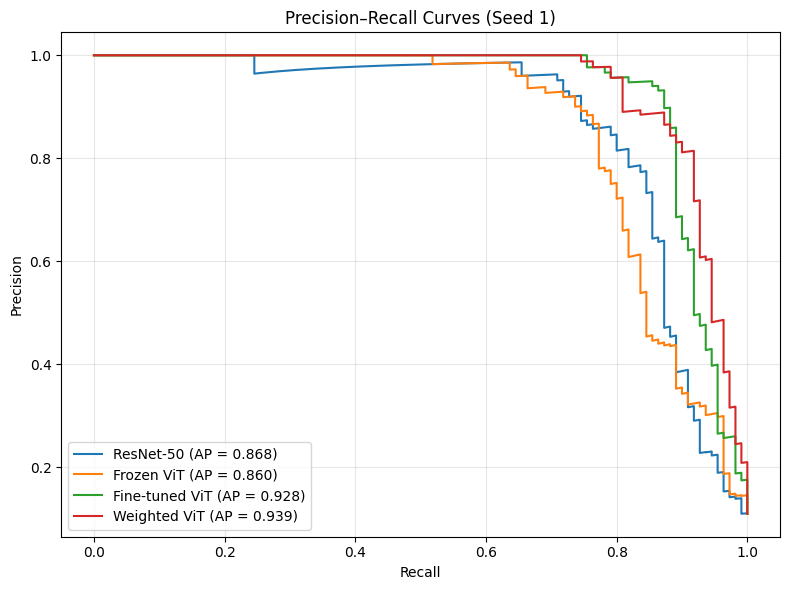

Precision-recall curves saved successfully.


In [37]:
#Comparing precision-recall curves for the four models
models_to_compare = [
    ("ResNet-50", "resnet", False, "resnet50_weighted"),
    ("Frozen ViT", "vit", True, "vit_frozen"),
    ("Fine-tuned ViT", "vit", False, "vit_normal"),
    ("Weighted ViT", "vit", False, "vit_weighted")
]

plt.figure(figsize=(8, 6))

for name, model_type, frozen, file_name in models_to_compare:
    model = create_model(model_type, frozen=frozen)

    #Loading the saved seed 1 checkpoint
    checkpoint = f"{RESULTS_DIR}/{file_name}_seed1.pth"

    model.load_state_dict(
        torch.load(checkpoint, map_location=device, weights_only=True)
    )

    #Getting predictions from the test set
    results = evaluate_model(model, test_loader)

    precision, recall, _ = precision_recall_curve(
        results["labels"],
        results["probabilities"]
    )

    plt.plot(
        recall,
        precision,
        label=f"{name} (AP = {results['ap']:.3f})"
    )

    #Free the model before loading the next one
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves (Seed 1)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(f"{RESULTS_DIR}/pr_curves.png", dpi=300)
plt.show()

print("Precision-recall curves saved successfully.")



## Confusion Matrix Comparison

Confusion matrices show how many normal and defective images are classified correctly or incorrectly.

This comparison uses the four main model configurations with seed 1 and the standard classification threshold of 0.5.

False negatives represent defective images incorrectly classified as normal. In industrial inspection, these errors are particularly important because defects may go undetected.


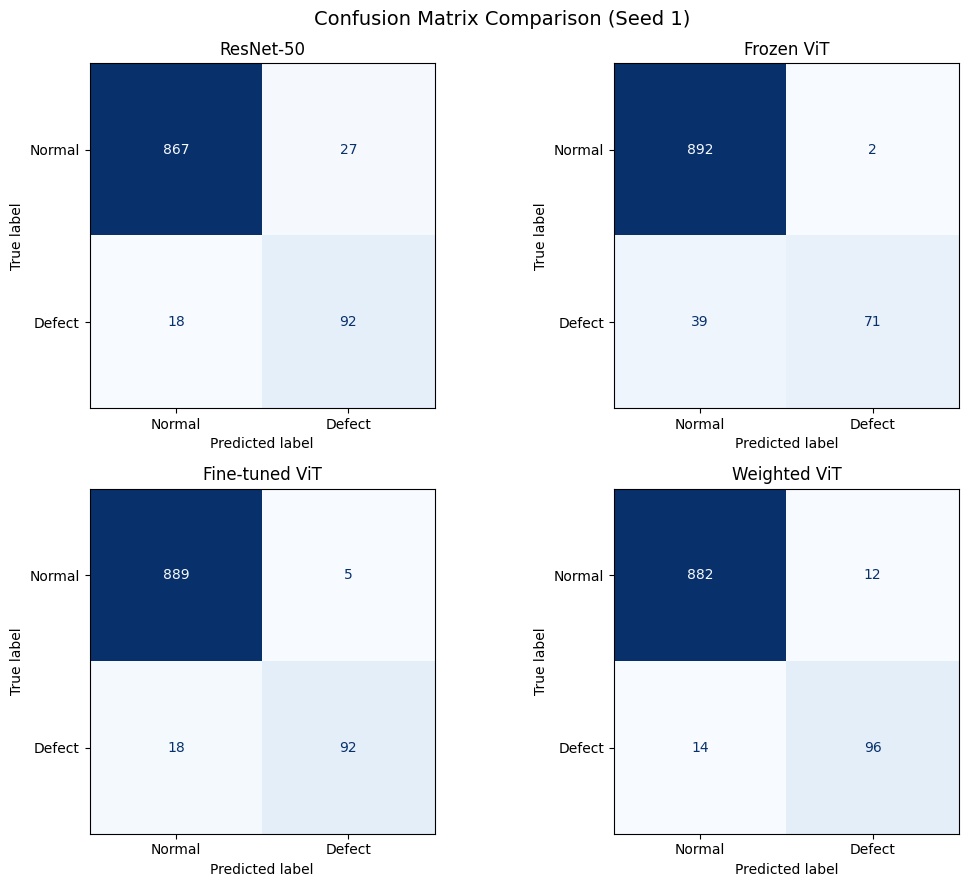

Confusion matrices saved successfully.


In [39]:
from sklearn.metrics import ConfusionMatrixDisplay
#Confusion matrices for the four main models
models_to_compare = [
    ("ResNet-50", "resnet", False, "resnet50_weighted"),
    ("Frozen ViT", "vit", True, "vit_frozen"),
    ("Fine-tuned ViT", "vit", False, "vit_normal"),
    ("Weighted ViT", "vit", False, "vit_weighted")
]

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, (name, model_type, frozen, file_name) in zip(
    axes.flatten(), models_to_compare
):
    model = create_model(model_type, frozen=frozen)

    #Loading seed 1 checkpoint
    checkpoint = f"{RESULTS_DIR}/{file_name}_seed1.pth"

    model.load_state_dict(
        torch.load(checkpoint, map_location=device, weights_only=True)
    )

    #Evaluating on the test set
    results = evaluate_model(model, test_loader)

    cm = results["confusion_matrix"]

    #Plotting the confusion matrix
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Normal", "Defect"]
    )

    disp.plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

plt.suptitle("Confusion Matrix Comparison (Seed 1)", fontsize=14)
plt.tight_layout()

plt.savefig(
    f"{RESULTS_DIR}/confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrices saved successfully.")



## Training Curves

Training curves show how model performance changes over the training epochs.

The validation F1-scores of the four main models are compared using seed 1.

These curves help identify differences in training behaviour, including fluctuations in validation performance.


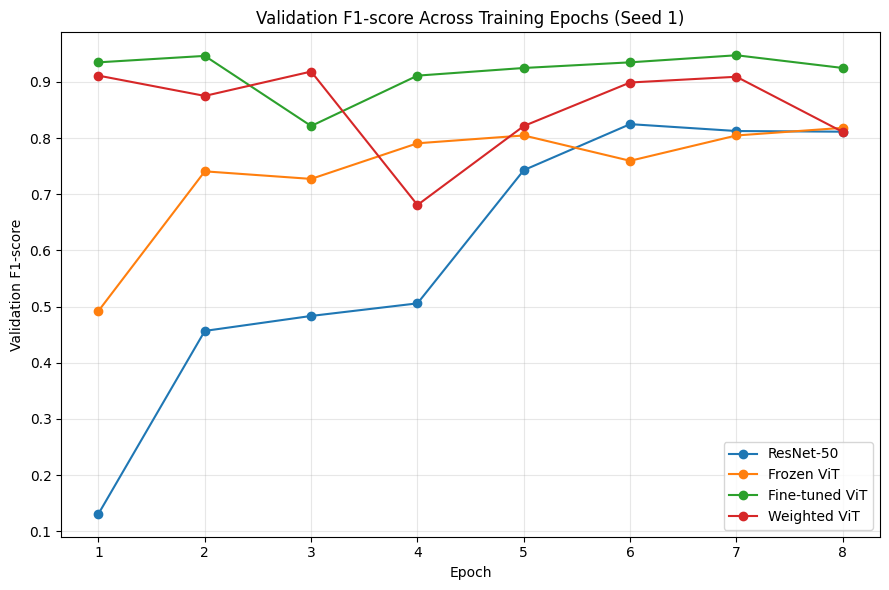

Training curves saved successfully.


In [42]:
#Plottimng validation F1-score across training epochs

history_files = {
    "ResNet-50": "resnet50_seed1_history.csv",
    "Frozen ViT": "vit_frozen_seed1_history.csv",
    "Fine-tuned ViT": "vit_normal_seed1_history.csv",
    "Weighted ViT": "vit_weighted_seed1_history.csv"
}

plt.figure(figsize=(9, 6))

for model_name, file_name in history_files.items():
    history = pd.read_csv(f"{RESULTS_DIR}/{file_name}")

    plt.plot(
        history["epoch"],
        history["val_f1"],
        marker="o",
        label=model_name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation F1-score")
plt.title("Validation F1-score Across Training Epochs (Seed 1)")
plt.xticks(range(1, EPOCHS + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{RESULTS_DIR}/training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Training curves saved successfully.")




## Error Analysis

Error analysis examines images that the model classified incorrectly.

This analysis focuses on the weighted ViT trained with seed 1, using the standard classification threshold of 0.5.

False negatives are defective images incorrectly predicted as normal, while false positives are normal images incorrectly predicted as defective.

Examining these errors can help identify possible challenges in detecting small or visually subtle defects.


In [43]:
#Identifying incorrectly classified test images
test_pred_labels = (test_probs >= 0.5).astype(int)

#Finding false negatives and false positives
false_negative_indices = np.where(
    (test_labels == 1) & (test_pred_labels == 0)
)[0]

false_positive_indices = np.where(
    (test_labels == 0) & (test_pred_labels == 1)
)[0]

print("False negatives (missed defects):", len(false_negative_indices))
print("False positives (false alarms):", len(false_positive_indices))

print("\nFirst five false negative indices:", false_negative_indices[:5])
print("First five false positive indices:", false_positive_indices[:5])


False negatives (missed defects): 14
False positives (false alarms): 12

First five false negative indices: [141 159 228 236 544]
First five false positive indices: [ 43 126 151 196 526]


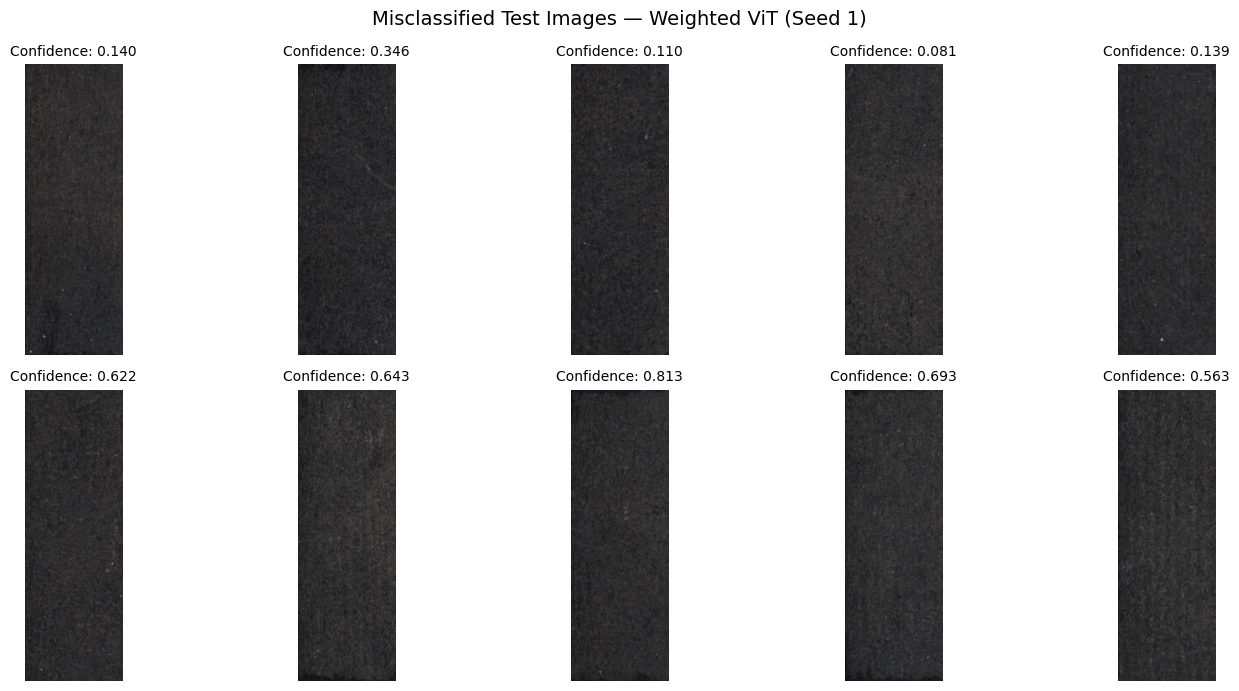

Error analysis figure saved successfully.


In [44]:

# Displaying examples of incorrectly classified images
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

# Selecting the first five false negatives and false positives
selected_fn = false_negative_indices[:5]
selected_fp = false_positive_indices[:5]

for row, indices in enumerate([selected_fn, selected_fp]):
    for col, index in enumerate(indices):
        # Loading the image from the test dataset
        image, label = test_dataset[int(index)]

        # Converting the tensor back into a displayable image
        image = image.permute(1, 2, 0).cpu().numpy()
        image = image * np.array(std) + np.array(mean)
        image = np.clip(image, 0, 1)

        axes[row, col].imshow(image)
        axes[row, col].set_title(
            f"Confidence: {test_probs[index]:.3f}",
            fontsize=10
        )
        axes[row, col].axis("off")

# Adding row labels
axes[0, 0].set_ylabel("Missed Defects", fontsize=12)
axes[1, 0].set_ylabel("False Alarms", fontsize=12)

plt.suptitle(
    "Misclassified Test Images — Weighted ViT (Seed 1)",
    fontsize=14
)
plt.tight_layout()

plt.savefig(
    f"{RESULTS_DIR}/error_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Error analysis figure saved successfully.")



## Final Output Verification

The final step checks whether the experimental results, evaluation tables, figures, and model checkpoints have been saved successfully.

This helps confirm that the outputs required for the technical report are available.


In [45]:
from pathlib import Path

results_folder = Path(RESULTS_DIR)

required_files = [
    "class_distribution.png",
    "multi_seed_results.csv",
    "multi_seed_summary.csv",
    "high_res_results.csv",
    "threshold_validation.csv",
    "threshold_test_comparison.csv",
    "pr_curves.png",
    "confusion_matrices.png",
    "training_curves.png",
    "error_analysis.png"
]

print("Checking final results and figures:\n")

missing_files = []

for file_name in required_files:
    file_path = results_folder / file_name

    if file_path.exists():
        print("FOUND:", file_name)
    else:
        print("MISSING:", file_name)
        missing_files.append(file_name)

#Checking training histories and saved checkpoints
history_files = list(results_folder.glob("*_history.csv"))
checkpoint_files = list(results_folder.glob("*.pth"))

print("\nTraining history files:", len(history_files))
print("Model checkpoints:", len(checkpoint_files))

if len(missing_files) == 0:
    print("\nAll required results and figures are saved!")
else:
    print("\nMissing files:", missing_files)


Checking final results and figures:

FOUND: class_distribution.png
FOUND: multi_seed_results.csv
FOUND: multi_seed_summary.csv
FOUND: high_res_results.csv
FOUND: threshold_validation.csv
FOUND: threshold_test_comparison.csv
FOUND: pr_curves.png
FOUND: confusion_matrices.png
FOUND: training_curves.png
FOUND: error_analysis.png

Training history files: 13
Model checkpoints: 13

All required results and figures are saved!
